# Two Climate Futures: data setup + static visualization ideas

This notebook downloads the CMIP6 data used in the proposal and builds four more static views of where
the high-emissions future (SSP5-8.5) adds the most heat compared with the low-emissions future (SSP1-2.6).

**Data:** NASA GISS-E2-1-G, monthly near-surface air temperature (`tas`, table `Amon`), member `r1i1p3f1`,
scenarios SSP1-2.6 / SSP2-4.5 / SSP5-8.5, 2020–2100. It's read straight from the public
[Pangeo CMIP6 archive on Google Cloud](https://pangeo-data.github.io/pangeo-cmip6-cloud/) (no account needed).
`r1i1p3f1` is the first ensemble member with all three scenarios available in that archive.

The first run downloads about 150 MB and caches a small summary in `data/`. Later runs read the cache.

Requirements: `pip install xarray "zarr>=3" gcsfs cftime matplotlib pandas`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

SCENARIOS = {
    "ssp126": "SSP1-2.6",
    "ssp245": "SSP2-4.5",
    "ssp585": "SSP5-8.5",
}
COLORS = {"ssp126": "#2b6cb0", "ssp245": "#d69e2e", "ssp585": "#c53030"}
START, END = 2020, 2100
STORE = "gs://cmip6/CMIP6/ScenarioMIP/NASA-GISS/GISS-E2-1-G/{exp}/r1i1p3f1/Amon/tas/gn/v20200115/"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

## 1. Download and summarize

The full grid is 2° lat × 2.5° lon, monthly. Two summaries go into the cache:

- **zonal means** (`month × latitude`, °C): every longitude is equally weighted, so area-weighted regional
  and global means can be computed exactly from these with `cos(latitude)` weights.
- **annual-mean grids** (`year × lat × lon`, °C): kept for later map work and the browser CSVs.

In [2]:
CACHE = DATA_DIR / "giss_tas_summary.npz"


def download():
    import xarray as xr

    coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    out = {}
    for exp in SCENARIOS:
        ds = xr.open_zarr(STORE.format(exp=exp), consolidated=True,
                          storage_options={"token": "anon"}, decode_times=coder)
        tas = ds["tas"].sel(time=slice(str(START), str(END))).load() - 273.15
        years = np.array([t.year for t in tas.time.values])
        months = np.array([t.month for t in tas.time.values])
        out[f"{exp}_zonal"] = tas.mean("lon").values.astype("float32")
        out[f"{exp}_annual"] = np.stack(
            [tas.values[years == y].mean(axis=0) for y in range(START, END + 1)]
        ).astype("float32")
        out["lat"], out["lon"] = tas.lat.values, tas.lon.values
        out["years"], out["months"] = years, months
        print(f"{exp}: {tas.shape}")
    np.savez_compressed(CACHE, **out)


if not CACHE.exists():
    download()
d = dict(np.load(CACHE))
lat, years, months = d["lat"], d["years"], d["months"]
YEARS = np.arange(START, END + 1)
print(f"lat {lat.min()}..{lat.max()} ({lat.size}), {years.min()}-{years.max()}, {years.size} months")

lat -89.0..89.0 (90), 2020-2100, 972 months


In [3]:
weights = np.cos(np.deg2rad(lat))

REGIONS = {
    "Arctic": lat >= 66.5,
    "Tropics": np.abs(lat) <= 23.5,
    "Global": np.ones_like(lat, dtype=bool),
}


def annual(zonal):
    """Monthly (month, lat) -> annual (year, lat)."""
    return np.stack([zonal[years == y].mean(axis=0) for y in YEARS])


zonal_annual = {exp: annual(d[f"{exp}_zonal"]) for exp in SCENARIOS}


def regional_series(exp, mask):
    z = zonal_annual[exp][:, mask]
    w = weights[mask]
    return (z * w).sum(axis=1) / w.sum()


regional = pd.DataFrame(
    {(exp, name): regional_series(exp, mask) for exp in SCENARIOS for name, mask in REGIONS.items()},
    index=YEARS,
)
regional.columns.names = ["scenario", "region"]
regional.loc[[2020, 2050, 2100]].round(2)

scenario ssp126                ssp245                ssp585               
region   Arctic Tropics Global Arctic Tropics Global Arctic Tropics Global
2020     -12.24   26.44  15.00 -12.48   26.69  15.03 -11.13   27.20  15.36
2050      -9.40   27.87  16.20  -9.29   27.86  16.11  -8.92   28.36  16.62
2100     -10.28   27.23  15.93  -9.21   28.41  16.81  -5.12   30.44  18.87

## Viz A: Regional time series (Arctic vs tropics vs global, both scenarios)

Each line is the change from that region's own 2020–2029 average. Using change instead of absolute
temperature puts a −15 °C Arctic and a 26 °C tropics on the same axis. Thin lines are annual values and
thick lines are an 11-year rolling mean.

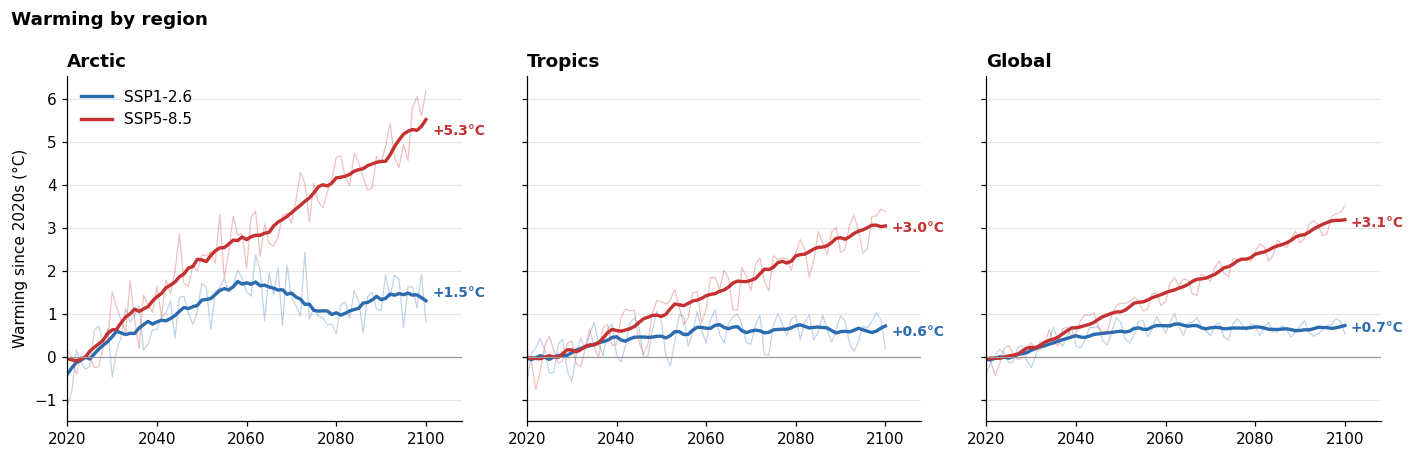

In [4]:
BASE = slice(2020, 2029)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, region in zip(axes, REGIONS):
    for exp in ["ssp126", "ssp585"]:
        s = regional[(exp, region)]
        anom = s - s.loc[BASE].mean()
        ax.plot(anom.index, anom, color=COLORS[exp], alpha=0.3, lw=0.8)
        ax.plot(anom.index, anom.rolling(11, center=True, min_periods=6).mean(),
                color=COLORS[exp], lw=2.2, label=SCENARIOS[exp])
        ax.annotate(f"{anom.loc[2091:2100].mean():+.1f}°C", (2100, anom.loc[2091:2100].mean()),
                    xytext=(4, 0), textcoords="offset points", va="center",
                    color=COLORS[exp], fontsize=9, fontweight="bold")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_title(region, loc="left", fontweight="bold")
    ax.set_xlim(2020, 2108)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("Warming since 2020s (°C)")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Warming by region", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "regional-timeseries.png")
plt.show()

## Viz B: Latitude × year heatmap of the difference (SSP5-8.5 − SSP1-2.6)

Zonal-mean annual difference. Each column is a year and each row is a latitude band. This one view shows
both *when* the futures separate and *where* the gap is largest. The scale is diverging and centered on zero
so that the regions where SSP5-8.5 is still cooler in the early years remain visible.

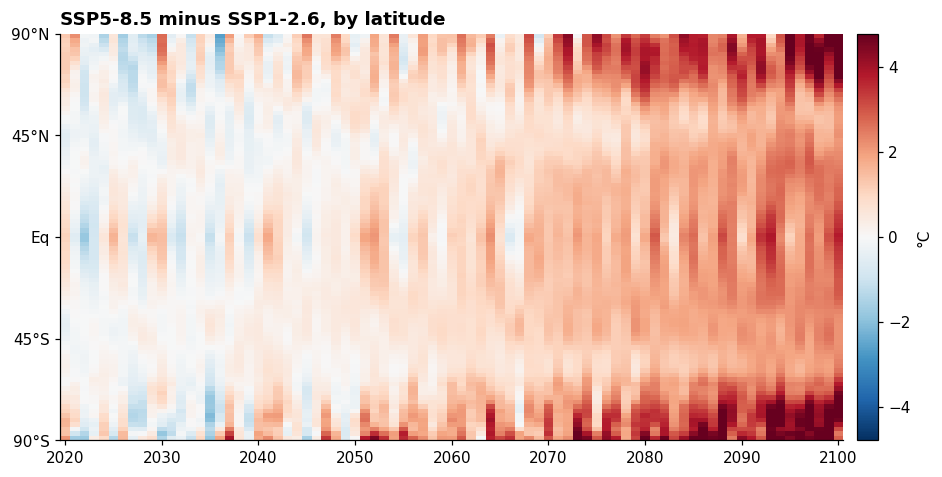

In [5]:
diff_lat_year = zonal_annual["ssp585"] - zonal_annual["ssp126"]
vmax = np.nanpercentile(np.abs(diff_lat_year), 99)

fig, ax = plt.subplots(figsize=(11, 4.8))
mesh = ax.pcolormesh(YEARS, lat, diff_lat_year.T, cmap="RdBu_r",
                     norm=mcolors.TwoSlopeNorm(0, -vmax, vmax), shading="nearest")
ax.set_yticks([-90, -45, 0, 45, 90], ["90°S", "45°S", "Eq", "45°N", "90°N"])
cb = fig.colorbar(mesh, ax=ax, pad=0.015)
cb.set_label("°C")
ax.set_title("SSP5-8.5 minus SSP1-2.6, by latitude", loc="left", fontweight="bold")
fig.savefig(FIG_DIR / "latitude-year-difference.png")
plt.show()

## Viz C: End-of-century warming by latitude, all three scenarios

Warming from 2020–2039 to 2081–2100 in each latitude band, for all three scenarios. The space between the
lines shows how much each step up in emissions adds at each latitude. It may also help decide whether the
middle scenario earns a place in the story, since it falls clearly between the other two.

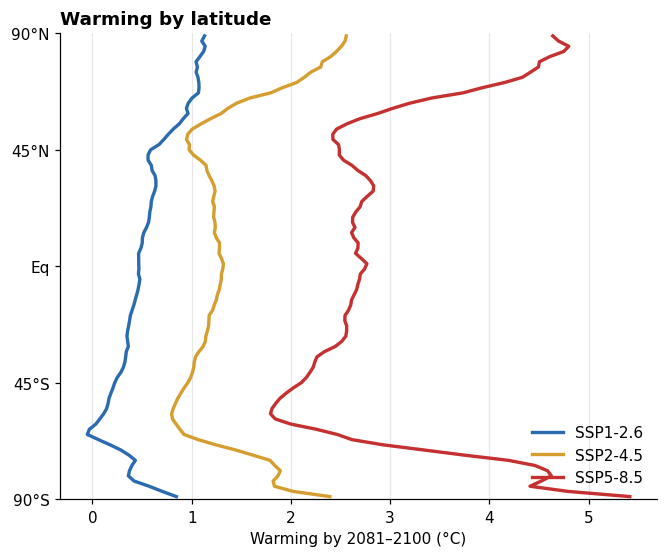

In [6]:
early = (YEARS >= 2020) & (YEARS <= 2039)
late = (YEARS >= 2081) & (YEARS <= 2100)

fig, ax = plt.subplots(figsize=(7, 5.5))
for exp in SCENARIOS:
    warming = zonal_annual[exp][late].mean(0) - zonal_annual[exp][early].mean(0)
    ax.plot(warming, lat, color=COLORS[exp], lw=2.2, label=SCENARIOS[exp])
ax.set_yticks([-90, -45, 0, 45, 90], ["90°S", "45°S", "Eq", "45°N", "90°N"])
ax.set_ylim(-90, 90)
ax.set_xlabel("Warming by 2081–2100 (°C)")
ax.grid(axis="x", alpha=0.3)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Warming by latitude", loc="left", fontweight="bold")
fig.savefig(FIG_DIR / "warming-by-latitude.png")
plt.show()

## Viz D: Month × latitude: when in the year the extra heat lands (2081–2100)

The proposal maps use January only. This view averages the SSP5-8.5 − SSP1-2.6 difference over 2081–2100
for each calendar month and latitude, which shows whether January is a representative month to feature. It
can help decide which month the interactive map opens on and which annotations to add.

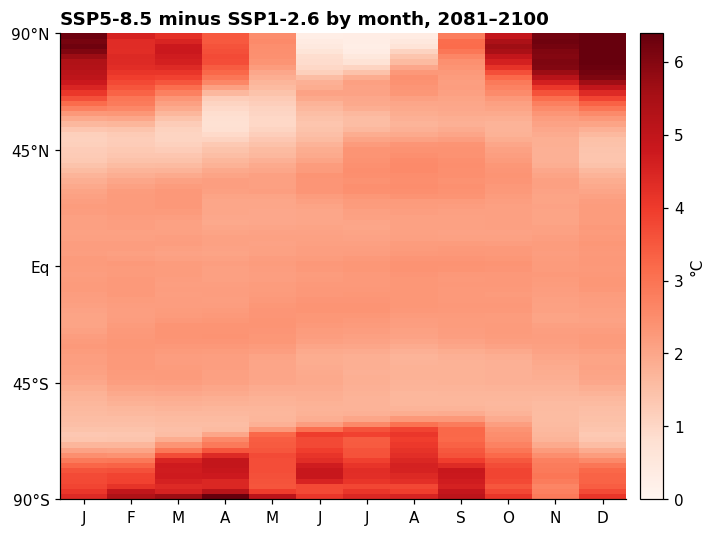

In [7]:
late_m = (years >= 2081) & (years <= 2100)
diff_month_lat = np.stack([
    (d["ssp585_zonal"] - d["ssp126_zonal"])[late_m & (months == m)].mean(0) for m in range(1, 13)
])

fig, ax = plt.subplots(figsize=(8, 5.5))
mesh = ax.pcolormesh(np.arange(1, 13), lat, diff_month_lat.T, cmap="Reds",
                     vmin=0, vmax=np.nanpercentile(diff_month_lat, 99.5), shading="nearest")
ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_yticks([-90, -45, 0, 45, 90], ["90°S", "45°S", "Eq", "45°N", "90°N"])
cb = fig.colorbar(mesh, ax=ax, pad=0.02)
cb.set_label("°C")
ax.set_title("SSP5-8.5 minus SSP1-2.6 by month, 2081–2100", loc="left", fontweight="bold")
fig.savefig(FIG_DIR / "month-latitude-difference.png")
plt.show()

## Notes for the team

- All four figures are saved in `figures/` next to the original proposal figures.
- Titles state a takeaway. Check them against the rendered numbers before using them in the proposal.
- Limitation: this is one model and one ensemble member, so the curves are not smoothed by averaging across
  members. Year-to-year wiggles, especially in the Arctic, are internal variability, not scenario signal.
- `d["<exp>_annual"]` holds annual-mean grids (year × lat × lon) if we want to export new CSVs for the
  browser map.